# Backtest 3 · Hourly walk-forward (Vantage spreads)

TRAIN 2019 – 2022: try 36 parameter combinations, keep crosses that made money before costs, pick the best after-cost Sharpe. TEST 2023 → latest: run that single choice untouched.

In [1]:
from dataclasses import dataclass, replace
from dataclasses import replace
from itertools import product
from pathlib import Path
import argparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
pd.set_option("display.width", 200)
ROOT = Path.cwd().parent   # repository root (run the notebook from its own folder); data lives in ROOT / "data"

### Forex PCA residual model

In [2]:
CCYS = ["EUR", "GBP", "AUD", "NZD", "CAD", "CHF", "JPY", "NOK", "SEK", "XAU", "XAG"]

CROSSES_8 = {  # symbol: (base, quote)
    "AUDNZD": ("AUD", "NZD"), "EURGBP": ("EUR", "GBP"), "EURCHF": ("EUR", "CHF"),
    "AUDCAD": ("AUD", "CAD"), "NZDCAD": ("NZD", "CAD"), "CADCHF": ("CAD", "CHF"),
    "EURNOK": ("EUR", "NOK"), "EURSEK": ("EUR", "SEK"),
}

# all 23 crosses downloaded (data_collection/01): the 8 above + the rest of the 28 pairs without USD
CROSSES_ALL = {**CROSSES_8, **{s: (s[:3], s[3:]) for s in [
    "EURJPY", "GBPJPY", "AUDJPY", "NZDJPY", "CADJPY", "CHFJPY", "EURAUD", "EURNZD",
    "EURCAD", "GBPAUD", "GBPNZD", "GBPCAD", "GBPCHF", "AUDCHF", "NZDCHF"]}}

# HistData has no spreads: assumed typical prop-firm raw spreads, as % of price (conservative)
SPREAD_PCT = {"AUDNZD": 0.018, "EURGBP": 0.012, "EURCHF": 0.016, "AUDCAD": 0.016,
              "NZDCAD": 0.024, "CADCHF": 0.025, "EURNOK": 0.035, "EURSEK": 0.036}

COMMISSION_PCT = 0.003  # per side, ~ $6 per 100k round turn
BARS_PER_YEAR = 5900  # hourly bars actually present per year in the data
CROSSES = CROSSES_8   # active universe; later cells may switch it to CROSSES_ALL

In [3]:
@dataclass(frozen=True)
class Params:
    window: int = 480
    step: int = 24
    k: int = 3                 # PCA factors removed
    entry: float = 2.0
    exit: float = 0.5
    stop: float = 4.0
    max_hl: float = 48.0
    max_hold: int = 96
    target_vol: float = 0.05   # annual vol per open position
    max_lev: float = 30.0
    spread_mult: float = 1.0
    real_spreads: bool = False  # True: per-bar spreads recorded by Vantage MT5 (data/mt5_fx)
    bars_per_year: float = BARS_PER_YEAR  # 5900 for H1; set for other timeframes
    vol_lookback: int = 480     # bars used to size positions

In [4]:
_MT5_SPREADS = None

def mt5_spreads(idx):
    """Per-bar spread as a fraction of price for each cross, from data_collection/02, aligned to idx.
    Bars missing in the MT5 history get that symbol's median spread."""
    global _MT5_SPREADS
    if _MT5_SPREADS is None:
        _MT5_SPREADS = pd.read_csv(ROOT / "data/mt5_fx/crosses_1h.csv", index_col=0, parse_dates=True)
    out = {}
    for sym in CROSSES:
        s = _MT5_SPREADS[f"{sym}_spread"]
        out[sym] = s.reindex(idx).fillna(s.median()).to_numpy()
    return out

In [5]:
def model_signals(r, pairs, prm):
    """Out-of-sample residuals and s-scores for each cross. r: (T, N) log returns of CCYS."""
    T = len(r)
    P = len(pairs)
    s = np.full((T, P), np.nan)
    hl = np.full((T, P), np.nan)
    resid = np.full((T, P), np.nan)
    explained = np.full(T, np.nan)
    for t0 in range(prm.window, T, prm.step):
        w = r[t0 - prm.window:t0]
        mu, sd = w.mean(0), w.std(0, ddof=1)
        z = (w - mu) / sd
        vals, vecs = np.linalg.eigh(np.corrcoef(z.T))
        o = vals.argsort()[::-1]
        V = vecs[:, o[:prm.k]]
        t1 = min(t0 + prm.step, T)
        explained[t0:t1] = vals[o[0]] / vals.sum()
        e_win = (z - z @ V @ V.T) * sd                         # residual returns, window
        zn = (r[t0:t1] - mu) / sd
        e_new = (zn - zn @ V @ V.T) * sd                       # residual returns, next bars (frozen model)
        for j, (a, b) in enumerate(pairs):
            p_win = e_win[:, a] - e_win[:, b]
            p_new = e_new[:, a] - e_new[:, b]
            resid[t0:t1, j] = p_new
            x = np.cumsum(p_win)
            bb, aa = np.polyfit(x[:-1], x[1:], 1)
            if not 0 < bb < 1:
                continue
            zeta = x[1:] - (aa + bb * x[:-1])
            m = aa / (1 - bb)
            sig = np.sqrt(zeta.var() / (1 - bb * bb))
            s[t0:t1, j] = (x[-1] + np.cumsum(p_new) - m) / sig
            hl[t0:t1, j] = np.log(2) / -np.log(bb)
    return s, hl, resid, explained

In [6]:
def backtest_one(px, s, hl, idx, cost_side, prm, carry=0.0):
    """One cross. px: closes, s/hl: signals at each bar close, cost_side: cost per side (scalar or per bar),
    carry: holding cost per bar while a position is open (swap), as a fraction of notional."""
    cost_side = np.broadcast_to(np.asarray(cost_side, dtype=float), (len(px),))
    carry = np.broadcast_to(np.asarray(carry, dtype=float), (len(px),))
    simple = np.r_[0.0, px[1:] / px[:-1] - 1]
    lr = np.r_[0.0, np.diff(np.log(px))]
    bar_target = prm.target_vol / np.sqrt(prm.bars_per_year)
    n = len(px)
    ret, gross = np.zeros(n), np.zeros(n)
    pos, lev, held, blocked, cur, trades = 0, 0.0, 0, 0, None, []
    for t in range(n):
        if pos != 0:
            g = pos * lev * simple[t]
            ret[t] += g - lev * carry[t]
            gross[t] += g
            cur["gross"] += g
            cur["cost"] += lev * carry[t]
            held += 1
        st = s[t]
        want, reason = pos, None
        if pos != 0:
            if np.isnan(st):
                want, reason = 0, "model invalid"
            elif (pos > 0 and st >= -prm.exit) or (pos < 0 and st <= prm.exit):
                want, reason = 0, "target"
            elif abs(st) >= prm.stop:
                want, reason = 0, "stop"
            elif held >= prm.max_hold:
                want, reason = 0, "time"
        if blocked and (np.isnan(st) or abs(st) < prm.entry):
            blocked = 0
        if want == 0 and pos == 0 and not blocked and not np.isnan(st) \
                and hl[t] <= prm.max_hl and prm.entry <= abs(st) < prm.stop:
            want = -1 if st > 0 else 1
        if want != pos:
            if pos != 0:
                ret[t] -= lev * cost_side[t]
                cur.update(cost=cur["cost"] + lev * cost_side[t], exit=idx[t], bars=held, reason=reason)
                trades.append(cur)
                blocked = 1 if reason in ("stop", "time") else 0
            if want != 0:
                vol = lr[max(0, t - prm.vol_lookback):t + 1].std()
                lev = min(bar_target / vol, prm.max_lev) if vol > 0 else 0.0
                ret[t] -= lev * cost_side[t]
                cur = {"entry": idx[t], "dir": want, "s_entry": st, "half_life": hl[t], "lev": lev,
                       "gross": 0.0, "cost": lev * cost_side[t]}
                held = 0
            pos = want
    tr = pd.DataFrame(trades)
    if len(tr):
        tr["net"] = tr["gross"] - tr["cost"]
    return ret, gross, tr

In [7]:
def run(cur, crs, prm, sig=None):
    r = np.log(cur[CCYS]).diff().to_numpy()[1:]
    idx = cur.index[1:]
    pairs = [(CCYS.index(a), CCYS.index(b)) for a, b in CROSSES.values()]
    if sig is None:
        sig = model_signals(r, pairs, prm)
    s, hl, resid, explained = sig
    px_all = crs.reindex(idx).ffill()
    real = mt5_spreads(idx) if prm.real_spreads else None
    per, trades = {}, []
    for j, sym in enumerate(CROSSES):
        if real is not None:
            cost = real[sym] / 2 * prm.spread_mult + COMMISSION_PCT / 100
        else:
            cost = (SPREAD_PCT[sym] / 2 * prm.spread_mult + COMMISSION_PCT) / 100
        ret, gross, tr = backtest_one(px_all[sym].to_numpy(), s[:, j], hl[:, j], idx, cost, prm)
        per[sym] = (ret, gross, tr)
        if len(tr):
            tr.insert(0, "symbol", sym)
            trades.append(tr)
    eq = pd.DataFrame({"ret": sum(v[0] for v in per.values()),
                       "gross": sum(v[1] for v in per.values())}, index=idx)
    tr = pd.concat(trades, ignore_index=True) if trades else pd.DataFrame()
    return eq, tr, per, sig, idx

In [8]:
def variance_ratio(x, k):
    x = pd.Series(x).dropna()
    agg = x.rolling(k).sum().iloc[k - 1::k]
    return agg.var() / (k * x.var())

### Performance statistics and prop-firm challenge simulator

In [9]:
def stats(eq, tr, label=""):
    r = eq["ret"]
    equity = (1 + r).cumprod()
    years = len(r) / BARS_PER_YEAR
    dd = equity / equity.cummax() - 1
    sharpe = r.mean() / r.std() * np.sqrt(BARS_PER_YEAR) if r.std() > 0 else np.nan
    gross_sharpe = eq["gross"].mean() / eq["gross"].std() * np.sqrt(BARS_PER_YEAR)
    out = {
        "label": label,
        "CAGR %": (equity.iloc[-1] ** (1 / years) - 1) * 100,
        "Sharpe": sharpe,
        "Sharpe before costs": gross_sharpe,
        "max DD %": dd.min() * 100,
        "trades": len(tr),
        "trades/month": len(tr) / (years * 12),
        "win %": (tr["net"] > 0).mean() * 100 if len(tr) else np.nan,
        "avg hold (h)": tr["bars"].mean() if len(tr) else np.nan,
        "avg gross/trade %": tr["gross"].mean() * 100 if len(tr) else np.nan,
        "avg cost/trade %": tr["cost"].mean() * 100 if len(tr) else np.nan,
    }
    return out

In [10]:
def challenge(eq, scale=1.0, target=0.08, daily_loss=0.05, max_loss=0.10, max_days=120, every_days=5):
    """Replay the strategy from many start dates under prop-firm rules.
    scale multiplies risk (2.0 = twice the position size). Daily loss uses equity at the 22:00 UTC rollover."""
    r = eq["ret"].to_numpy() * scale
    day = (eq.index + pd.Timedelta(hours=2)).normalize()  # trading day rolls at 22:00 UTC
    day_codes, day_start = pd.factorize(day)[0], None
    starts = np.flatnonzero(np.r_[True, np.diff(day_codes) != 0])[::every_days]
    results = []
    for st in starts:
        e, peak_day_eq, d0, days, outcome, t = 1.0, 1.0, day_codes[st], 0, "unfinished", st
        day_start = 1.0
        while t < len(r):
            if day_codes[t] != d0:
                d0 = day_codes[t]
                day_start = e
                days += 1
                if days >= max_days:
                    break
            e *= 1 + r[t]
            if e <= day_start * (1 - daily_loss):
                outcome = "fail: daily loss"
                break
            if e <= 1 - max_loss:
                outcome = "fail: max loss"
                break
            if e >= 1 + target:
                outcome = "pass"
                break
            t += 1
        if t >= len(r) and outcome == "unfinished" and days < max_days:
            continue  # ran out of data, not a fair attempt
        results.append({"start": eq.index[st], "outcome": outcome, "days": days})
    return pd.DataFrame(results)

### Walk-forward settings and helpers

In [11]:
SPLIT = pd.Timestamp("2023-01-01", tz="UTC")

GRID = {
    "window": [480, 960],
    "entry": [1.5, 2.0, 2.5],
    "exit": [0.0, 0.5],
    "max_hl": [24.0, 48.0, 96.0],
}

In [12]:
def perf(ret):
    ret = pd.Series(ret)
    if ret.std() == 0 or len(ret) == 0:
        return {"Sharpe": np.nan, "return %/yr": 0.0, "max DD %": 0.0}
    eq = (1 + ret).cumprod()
    return {"Sharpe": ret.mean() / ret.std() * np.sqrt(BARS_PER_YEAR),
            "return %/yr": ret.mean() * BARS_PER_YEAR * 100,
            "max DD %": (eq / eq.cummax() - 1).min() * 100}

In [13]:
def portfolio(per, symbols, idx, mask):
    ret = sum(per[s][0] for s in symbols) if symbols else np.zeros(len(idx))
    gross = sum(per[s][1] for s in symbols) if symbols else np.zeros(len(idx))
    return pd.Series(ret[mask], index=idx[mask]), pd.Series(gross[mask], index=idx[mask])

In [14]:
def trades_in(per, symbols, lo, hi):
    t = [per[s][2].assign(symbol=s) for s in symbols if len(per[s][2])]
    t = pd.concat(t, ignore_index=True) if t else pd.DataFrame(columns=["entry", "net", "gross", "cost"])
    return t[(t["entry"] >= lo) & (t["entry"] < hi)]

## Walk-forward

In [15]:
d = ROOT / "data/histdata_fx"
cur = pd.read_csv(d / "currencies_1h.csv", index_col=0, parse_dates=True)[CCYS].dropna()
crs = pd.read_csv(d / "crosses_1h.csv", index_col=0, parse_dates=True)
pd.set_option("display.width", 220)

sig_cache, rows, keep = {}, [], {}
for window, entry, exit_, max_hl in product(*GRID.values()):
    prm = replace(Params(), window=window, entry=entry, exit=exit_, max_hl=max_hl, real_spreads=True)
    eq, tr, per, sig, idx = run(cur, crs, prm, sig_cache.get(window))
    sig_cache[window] = sig
    train, test = idx < SPLIT, idx >= SPLIT
    # cross selection uses TRAIN only: keep crosses with positive gross P&L before costs
    chosen = [s for s in CROSSES if per[s][1][train].sum() > 0]
    r_tr, _ = portfolio(per, chosen, idx, train)
    r_te, _ = portfolio(per, chosen, idx, test)
    key = (window, entry, exit_, max_hl)
    keep[key] = (per, chosen, idx)
    p_tr, p_te = perf(r_tr), perf(r_te)
    rows.append({"window": window, "entry": entry, "exit": exit_, "max_hl": max_hl,
                 "crosses": len(chosen),
                 "train trades": len(trades_in(per, chosen, idx[0], SPLIT)),
                 "TRAIN Sharpe": p_tr["Sharpe"], "TRAIN %/yr": p_tr["return %/yr"],
                 "test Sharpe": p_te["Sharpe"], "test %/yr": p_te["return %/yr"]})
    print(f"  {key}: train Sharpe {p_tr['Sharpe']:5.2f} | test Sharpe {p_te['Sharpe']:5.2f}", flush=True)

res = pd.DataFrame(rows).sort_values("TRAIN Sharpe", ascending=False)
res.to_csv(ROOT / "data/backtest_fx/walk_forward_grid.csv", index=False)
print("\nTop 10 by TRAIN Sharpe (the test columns are shown for transparency, not used to choose):")
print(res.head(10).round(2).to_string(index=False))

best = res.iloc[0]
key = (int(best["window"]), best["entry"], best["exit"], best["max_hl"])
per, chosen, idx = keep[key]
print(f"\n=== CHOSEN on 2019-2022: window {key[0]}, entry {key[1]}, exit {key[2]}, max half-life {key[3]}h ===")
print(f"crosses kept (positive before costs in train): {chosen}")

for label, mask, lo, hi in [("TRAIN 2019-2022", idx < SPLIT, idx[0], SPLIT),
                            ("TEST 2023-latest (untouched)", idx >= SPLIT, SPLIT, idx[-1] + pd.Timedelta(hours=1))]:
    r, g = portfolio(per, chosen, idx, mask)
    t = trades_in(per, chosen, lo, hi)
    p = perf(r)
    print(f"\n{label}:  Sharpe {p['Sharpe']:.2f} (before costs {perf(g)['Sharpe']:.2f})  "
          f"return {p['return %/yr']:.2f}%/yr  maxDD {p['max DD %']:.2f}%  trades {len(t)}  "
          f"win {(t['net'] > 0).mean() * 100:.0f}%  avg gross {t['gross'].mean() * 100:.4f}%  avg cost {t['cost'].mean() * 100:.4f}%")
    by_year = r.groupby(r.index.year).sum() * 100
    print("  by year %: " + "  ".join(f"{y}: {v:+.2f}" for y, v in by_year.items()))
    if mask[-1]:
        per_cross = {s: per[s][0][mask].sum() * 100 for s in chosen}
        print("  by cross %: " + "  ".join(f"{s}: {v:+.2f}" for s, v in per_cross.items()))
        eq = pd.DataFrame({"ret": r})
        print("  prop challenge in TEST period (+8%, 5% daily, 10% max, 120 days):")
        for scale in [1, 2, 4]:
            c = challenge(eq, scale=scale)
            vc = c["outcome"].value_counts(normalize=True) * 100
            print(f"    risk x{scale}: {len(c)} attempts | " + " | ".join(f"{k} {v:.0f}%" for k, v in vc.items()))

print("\nRobustness: how all 36 combinations did in TEST")
print(f"  positive test Sharpe: {(res['test Sharpe'] > 0).sum()} of {len(res)}   "
      f"median test Sharpe {res['test Sharpe'].median():.2f}   "
      f"corr(train Sharpe, test Sharpe) {res['TRAIN Sharpe'].corr(res['test Sharpe']):.2f}")

  (480, 1.5, 0.0, 24.0): train Sharpe  0.30 | test Sharpe -0.41


  (480, 1.5, 0.0, 48.0): train Sharpe  0.53 | test Sharpe -0.68


  (480, 1.5, 0.0, 96.0): train Sharpe  0.38 | test Sharpe -1.04


  (480, 1.5, 0.5, 24.0): train Sharpe  0.20 | test Sharpe -0.49


  (480, 1.5, 0.5, 48.0): train Sharpe  0.42 | test Sharpe -0.66


  (480, 1.5, 0.5, 96.0): train Sharpe  0.36 | test Sharpe -1.19


... (30 outputs left out)


Top 10 by TRAIN Sharpe (the test columns are shown for transparency, not used to choose):
 window  entry  exit  max_hl  crosses  train trades  TRAIN Sharpe  TRAIN %/yr  test Sharpe  test %/yr
    480    2.5   0.0    96.0        6          1477          0.53        3.19        -0.83      -5.24
    480    1.5   0.0    48.0        7          3876          0.53        4.76        -0.68      -5.79
    960    1.5   0.5    48.0        7          1459          0.53        2.65        -0.58      -2.70
    480    2.5   0.0    48.0        6          1334          0.46        2.50        -0.42      -2.20
    960    2.0   0.0    48.0        5           559          0.46        1.85         0.09       0.31
    960    2.0   0.0    96.0        6          1205          0.43        2.71        -0.44      -2.72
    480    1.5   0.5    48.0        7          4553          0.42        3.31        -0.66      -4.99
    960    2.5   0.0    96.0        5           516          0.42        1.79        -0.72   

    risk x1: 172 attempts | unfinished 89% | fail: max loss 11%


    risk x2: 176 attempts | unfinished 43% | fail: max loss 27% | pass 19% | fail: daily loss 11%


    risk x4: 193 attempts | pass 46% | fail: max loss 29% | fail: daily loss 24% | unfinished 1%

Robustness: how all 36 combinations did in TEST
  positive test Sharpe: 7 of 36   median test Sharpe -0.46   corr(train Sharpe, test Sharpe) -0.28


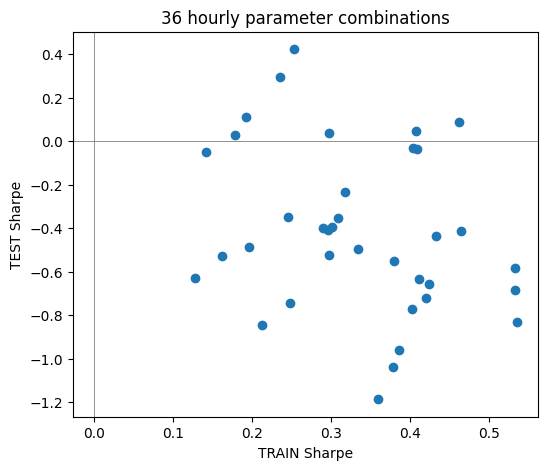

In [16]:
g = pd.read_csv(ROOT / "data/backtest_fx/walk_forward_grid.csv")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(g["TRAIN Sharpe"], g["test Sharpe"])
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("TRAIN Sharpe"); ax.set_ylabel("TEST Sharpe")
ax.set_title("36 hourly parameter combinations")
plt.show()

**Result:** the chosen hourly setup is about flat in the test period; only a few of the 36 combinations are positive. Hourly is not tradable after costs.